In [1]:
root = "M://Diploma/experiments/vesuvius/fragments"

### Data loading

For the baseline, we will do simple per-pixel classification. That is, we do not account for the neighborhood in any way. The only input we use are the raw pixel values from IR/CT.

Since fitting all 65 CT layers into RAM is infeasible (takes up more than 100 GB), here we will also select the most useful of those for further experiments, so that we do not have to worry about implementing models in external memory.

In [2]:
import numpy
import typing
import warnings
import PIL.Image

warnings.filterwarnings("ignore", category=PIL.Image.DecompressionBombWarning)

def load_fragment(fragment: int, depths: typing.Optional[typing.List[int]]):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0

    if depths is None:
        ir = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/ir.png")).ravel()[pixels]
        return numpy.expand_dims(ir, 1), ink

    ct = numpy.empty((len(pixels), len(depths)), dtype=numpy.float32)
    for i, depth in enumerate(depths):
        ct[:, i] = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]
    return ct, ink

def load_fragments(fragments, depths: typing.Optional[typing.List[int]]):
    values = list(load_fragment(fragments[0], depths))
    for fragment in fragments[1:]:
        fragment_values = load_fragment(fragment, depths)
        for i in range(len(values)):
            values[i] = numpy.concatenate([ values[i], fragment_values[i] ])
    return values

In [3]:
train_X, train_y = load_fragments([1, 2, 3], depths=None)
test_X, test_y = load_fragments([4], depths=None)

### Evaluation metrics

The main metric used in the competition is the $F_{0.5}$ score defined as follows:
$$ F_{0.5} = \dfrac{1.25 pr}{0.25 p + r} = \dfrac{1.25 TP}{1.25TP + FP + 0.25FN} $$
This metric scores precision higher than recall, which is designed to improve the ability to form coherent characters out of detected ink areas.

Additionally, for a more comprehensive evaluation, we compute the other typical segmentation metrics: per-pixel accuracy, precison, recall, F1-score, ROC-AUC, and Jaccard score.

For the leaderboard, the competition uses additional private data, which is not available in this project. To circumvent this, we will use Fragment 4 as a held-out test object used for evaluation. The results should generally reflect the scores in the competition, although direct comparison to the metrics reported there is not possible.

In [4]:
import numpy
import sklearn.metrics
import matplotlib.pyplot as plt

def estimate_quality(pred_proba: numpy.ndarray, masks: numpy.ndarray) -> dict:
    scores = pred_proba.flatten()
    preds = (scores >= 0.5).astype(numpy.int8)
    targets = masks.flatten().astype(numpy.int8)
    return {
        "F0.5": sklearn.metrics.fbeta_score(targets, preds, beta=0.5, zero_division=0),
        "Accuracy": sklearn.metrics.accuracy_score(targets, preds),
        "AUC-ROC": sklearn.metrics.roc_auc_score(targets, scores),
        "Precision": sklearn.metrics.precision_score(targets, preds, zero_division=0),
        "Recall": sklearn.metrics.recall_score(targets, preds, zero_division=0),
        "F1-score": sklearn.metrics.f1_score(targets, preds, zero_division=0),
        "Jaccard score": sklearn.metrics.jaccard_score(targets, preds, zero_division=0),
    }

def plot_prediction(pred_proba: numpy.ndarray, fragment: int, ax, thr: float = 0.5):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    prediction = numpy.zeros(mask.shape, dtype=bool)
    prediction[mask] = pred_proba.ravel() >= thr

    if ax is None:
        target = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")) > 0
        fig, axes = plt.subplots(1, 2, figsize=(4, 3))
        axes[0].imshow(target, cmap="gray", vmin=0, vmax=1)
        axes[0].set_title("Ink target")
        axes[1].imshow(prediction, cmap="gray", vmin=0, vmax=1)
        axes[1].set_title("Predicted ink")
        for ax in axes:
            ax.axis("off")
        fig.tight_layout()
        plt.show()
        plt.close(fig)
    else:
        ax.imshow(prediction, cmap="gray", vmin=0, vmax=1)
        ax.set_title("Predicted ink")
        ax.axis("off")

In all the following experiments, we explore two predictions: one formed from the infrared scans, and one from the 65 layers of the CT scans. The final evaluation matching the competition is only the latter one, yet the easier IR task is a simpler one that might give us some insight into the dataset and help devise a model for the harder part.

For this notebook, we also perform multiple CT experiments with different subsets of layers to find the ones that have no useful information and can be discarded from further experiments for performance reasons.
- Every second layer
- Every third layer
- Every fourth layer
- Layers 0 - 15: inner layers of the papyrus. We expect they are not useful.
- Layers 20 - 40: the writing edge. We expect they are the most useful.
- Layers 45 - 60: outer layers. We expect they are not useful.

### Dummy classifiers

First, let's try the simplest models that just predict constants.

In [5]:
import sklearn.dummy

def try_dummy(model: sklearn.dummy.DummyClassifier):
    train_X, train_y = load_fragments([1, 2, 3], depths=None)
    test_X, test_y = load_fragments([4], depths=None)

    model.fit(train_X, train_y)
    preds = model.predict_proba(test_X)[:, 1]
    scores = estimate_quality(preds, test_y)
    plot_prediction(preds, fragment=4, ax=None)
    return scores

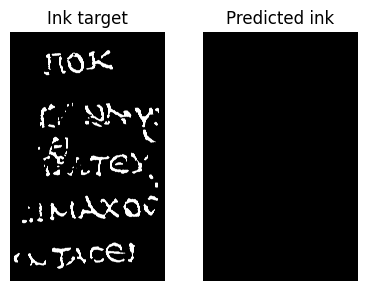

{'F0.5': 0.0,
 'Accuracy': 0.8961759286018581,
 'AUC-ROC': 0.5,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1-score': 0.0,
 'Jaccard score': 0.0}

In [ ]:
try_dummy(sklearn.dummy.DummyClassifier(strategy="constant", constant=0))

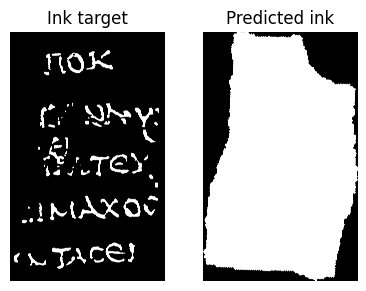

{'F0.5': 0.12649673766688765,
 'Accuracy': 0.10382407139814193,
 'AUC-ROC': 0.5,
 'Precision': 0.10382407139814193,
 'Recall': 1.0,
 'F1-score': 0.1881170633770194,
 'Jaccard score': 0.10382407139814193}

In [ ]:
try_dummy(sklearn.dummy.DummyClassifier(strategy="constant", constant=1))

The class imbalance here is obvious: only 10% of pixels are labeled as having inc.

### Basic models

In [6]:
import catboost
import sklearn.tree
import sklearn.ensemble
import sklearn.linear_model
import sklearn.preprocessing

models = {
    "Decision stump": sklearn.tree.DecisionTreeClassifier(
        class_weight={0: 1, 1: 5}, max_depth=1, random_state=42
    ),
    "Logistic regression": sklearn.linear_model.LogisticRegression(
        class_weight={0: 1, 1: 5}, random_state=42, n_jobs=1
    ),
    "Decision tree": sklearn.tree.DecisionTreeClassifier(
        class_weight={0: 1, 1: 5}, max_depth=7, random_state=42
    ),
    "Random forest": sklearn.ensemble.RandomForestClassifier(
        class_weight={0: 1, 1: 5}, max_depth=7, max_samples=0.05, random_state=42, n_jobs=1, verbose=0
    ),
    "Gradient boosting": sklearn.ensemble.HistGradientBoostingClassifier(
        class_weight={0: 1, 1: 5}, max_depth=4, random_state=42, verbose=0
    ),
    "CatBoost": catboost.CatBoostClassifier(
        class_weights=[1, 5], iterations=100, depth=4, random_seed=42, verbose=False
    ),
}

In [7]:
import gc
import pandas

def evaluate(model_name: str, *data):
    train_X, train_y, test_X, test_y = data
    model = sklearn.base.clone(models[model_name]).fit(train_X, train_y)
    return model, estimate_quality(model.predict_proba(test_X)[:, 1], test_y)

def run_experiment(experiment, depths):
    gc.collect()

    train_X, train_y = load_fragments([1, 2, 3], depths=depths)
    test_X, test_y = load_fragments([4], depths=depths)

    ss = sklearn.preprocessing.StandardScaler(copy=False)
    train_X = ss.fit_transform(train_X)
    test_X = ss.transform(test_X)

    runs, trained_models = [], []
    for name in models.keys():
        model, result = evaluate(name, train_X, train_y, test_X, test_y)
        runs.append({'Model': name, 'Experiment': experiment, **result})
        print(f"{name}: F0.5={result['F0.5']:.4f}")
        trained_models.append(model)
    return trained_models, pandas.DataFrame(runs)

In [8]:
def draw_feature_importance(importances, feature_names, title):
    print('Most important:', numpy.array(feature_names)[numpy.argsort(numpy.abs(importances))[::-1]])
    plt.figure(figsize=(6, 2))
    plt.plot(feature_names, importances)
    plt.xlabel("Feature index (layer)")
    plt.ylabel("Importance")
    plt.title(title)
    plt.show()

def analyze(trained_models, feature_names):
    print("DECISION STUMP")
    plt.figure(figsize=(6, 3))
    sklearn.tree.plot_tree(trained_models[0])
    plt.show()
    
    print("LOGISTIC REGRESSION")
    coef = trained_models[1].coef_[0]
    coef_df = pandas.DataFrame({"feature name": feature_names, "weight": coef})
    display(coef_df.set_index("feature name").transpose())
    print('Intercept:', trained_models[1].intercept_[0])
    draw_feature_importance(coef, feature_names, "Logistic regression")
    
    print("DECISION TREE")
    plt.figure(figsize=(10, 3))
    sklearn.tree.plot_tree(trained_models[2], max_depth=1)
    plt.show()
    draw_feature_importance(trained_models[2].feature_importances_, feature_names, "Decision tree")
    
    print("RANDOM FOREST")
    draw_feature_importance(trained_models[3].feature_importances_, feature_names, "Random forest")

    print("CATBOOST")
    draw_feature_importance(trained_models[5].feature_importances_, feature_names, "CatBoost")


#### Infrared

In [ ]:
ir_trained_models, ir_runs = run_experiment("IR", None)

Decision stump: F0.5=0.3167
Logistic regression: F0.5=0.2705
Decision tree: F0.5=0.3167
Random forest: F0.5=0.3167
Gradient boosting: F0.5=0.3167
CatBoost: F0.5=0.3167


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,IR,0.316713,0.755391,0.786141,0.274443,0.824949,0.411867,0.259341
1,Logistic regression,IR,0.270496,0.684867,0.876442,0.230713,0.871861,0.364873,0.223146
2,Decision tree,IR,0.316713,0.755391,0.876408,0.274443,0.824949,0.411867,0.259341
3,Random forest,IR,0.316713,0.755391,0.876415,0.274443,0.824949,0.411867,0.259341
4,Gradient boosting,IR,0.316713,0.755391,0.876435,0.274443,0.824949,0.411867,0.259341
5,CatBoost,IR,0.316713,0.755391,0.876428,0.274443,0.824949,0.411867,0.259341


DECISION STUMP


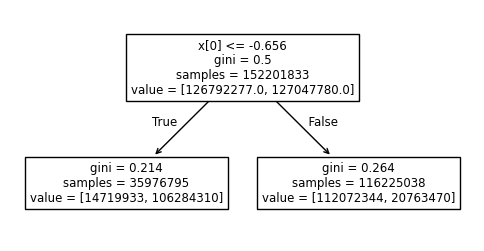

LOGISTIC REGRESSION


feature name,0
weight,-2.863715


Intercept: -1.6197187892004328
Most important: [0]


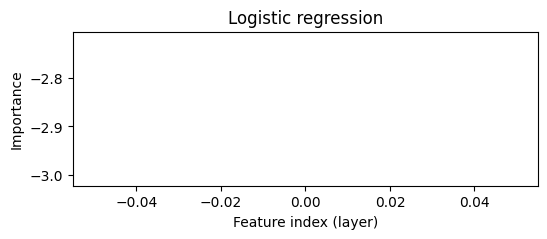

DECISION TREE


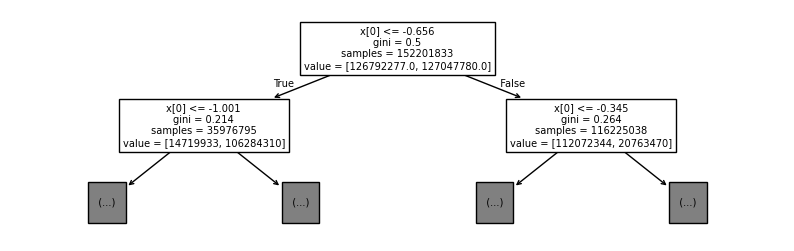

Most important: [0]


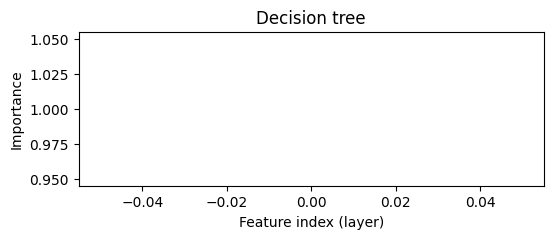

RANDOM FOREST
Most important: [0]


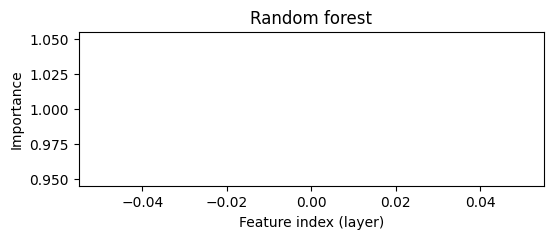

CATBOOST
Most important: [0]


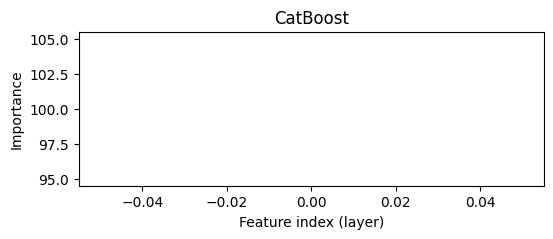

In [ ]:
display(ir_runs)
analyze(ir_trained_models, [0])

#### CT: every 2nd layer

In [9]:
e2_trained_models, e2_runs = run_experiment("Every_2nd", list(range(0, 65, 2)))

Decision stump: F0.5=0.1286
Logistic regression: F0.5=0.1309
Decision tree: F0.5=0.1324
Random forest: F0.5=0.1327
Gradient boosting: F0.5=0.1333
CatBoost: F0.5=0.1340


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Every_2nd,0.128603,0.597971,0.512416,0.109870,0.404440,0.172797,0.094569
1,Logistic regression,Every_2nd,0.130938,0.335352,0.520398,0.108546,0.748910,0.189610,0.104734
2,Decision tree,Every_2nd,0.132403,0.352677,0.540396,0.109870,0.737119,0.191235,0.105727
3,Random forest,Every_2nd,0.132718,0.278460,0.540534,0.109657,0.835702,0.193875,0.107343
4,Gradient boosting,Every_2nd,0.133265,0.301620,0.545796,0.110240,0.809857,0.194064,0.107459
5,CatBoost,Every_2nd,0.134024,0.318498,0.549278,0.110967,0.793536,0.194707,0.107853


DECISION STUMP


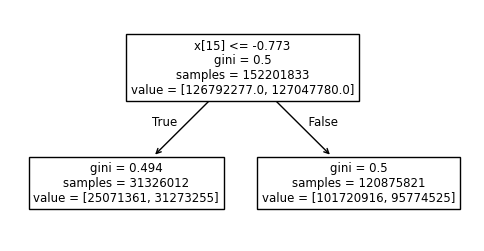

LOGISTIC REGRESSION


feature name,0,2,4,6,8,10,12,14,16,18,...,46,48,50,52,54,56,58,60,62,64
weight,0.009136,0.00358,0.012822,0.005936,0.010706,0.014568,0.008683,0.011803,0.011766,0.016942,...,-0.008659,0.00567,-0.00345,-0.001261,0.003247,-0.005736,0.00232,-0.00129,-0.008191,-0.004469


Intercept: -0.0002541503558095142
Most important: [20 36 18 10 22  4 38 14 16 32 26 44 40 24  8 30  0 12 46 62  6 56 48 42
 64  2 50 54 34 58 28 60 52]


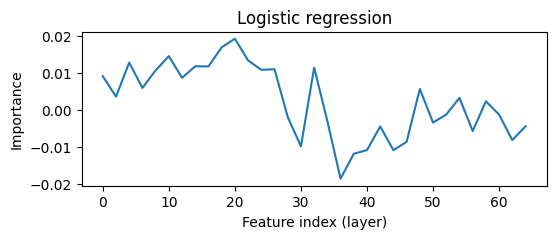

DECISION TREE


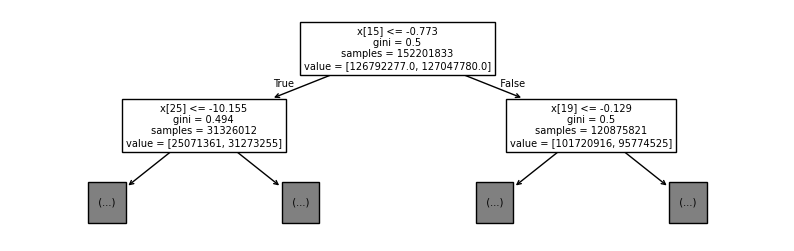

Most important: [28 36 30 38  8 16  0 50 26 32 34 24 64 22 58 52  4 62 20 10 40 46 60  6
 18 12  2 48 14 42 56 54 44]


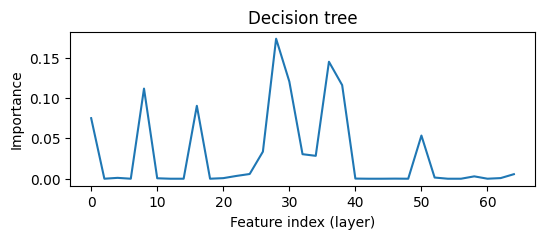

RANDOM FOREST
Most important: [30 32 28 34 20 26 36 24 18 22 38 14 16  8 12 10 40  6  2  4 42  0 64 46
 44 58 50 62 48 60 54 56 52]


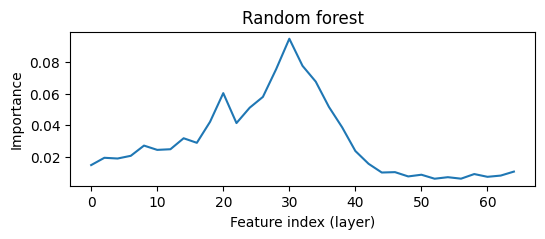

CATBOOST
Most important: [30 28 32 26 36 22 38  4 10 56 34  0 18 12 24 44  6  8  2 16 64 40 62 14
 58 20 42 52 46 60 50 54 48]


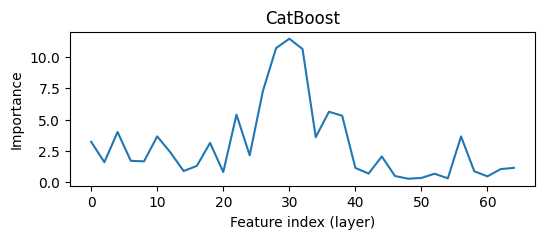

In [10]:
display(e2_runs)
analyze(e2_trained_models, list(range(0, 65, 2)))

#### CT: every 3rd layer

In [11]:
e3_trained_models, e3_runs = run_experiment("Every_3rd", list(range(0, 65, 3)))

Decision stump: F0.5=0.1286
Logistic regression: F0.5=0.1310
Decision tree: F0.5=0.1318
Random forest: F0.5=0.1326
Gradient boosting: F0.5=0.1330
CatBoost: F0.5=0.1339


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Every_3rd,0.128603,0.597971,0.512416,0.109870,0.404440,0.172797,0.094569
1,Logistic regression,Every_3rd,0.131036,0.335208,0.520610,0.108626,0.749810,0.189761,0.104826
2,Decision tree,Every_3rd,0.131816,0.400389,0.537362,0.109762,0.671563,0.188684,0.104170
3,Random forest,Every_3rd,0.132617,0.275437,0.539202,0.109558,0.838818,0.193803,0.107299
4,Gradient boosting,Every_3rd,0.133044,0.308907,0.543743,0.110104,0.798658,0.193527,0.107130
5,CatBoost,Every_3rd,0.133919,0.324549,0.547821,0.110921,0.784802,0.194370,0.107647


DECISION STUMP


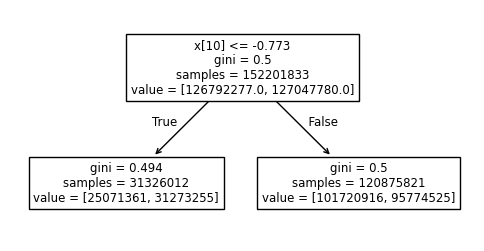

LOGISTIC REGRESSION


feature name,0,3,6,9,12,15,18,21,24,27,...,36,39,42,45,48,51,54,57,60,63
weight,0.009011,0.012459,0.012164,0.019117,0.015043,0.017982,0.024751,0.024258,0.019514,0.003412,...,-0.023064,-0.018938,-0.008834,-0.014154,0.000324,-0.000389,-0.000963,-0.001719,-0.00111,-0.01222


Intercept: -0.00025022806587754985
Most important: [18 21 36 24  9 39 15 12 45  3 63  6  0 42 33 30 27 57 60 54 51 48]


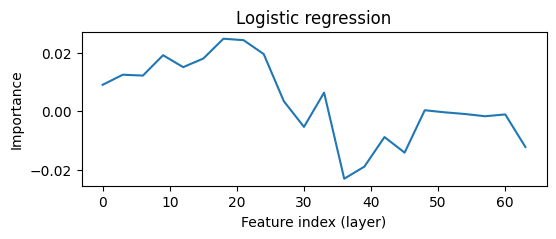

DECISION TREE


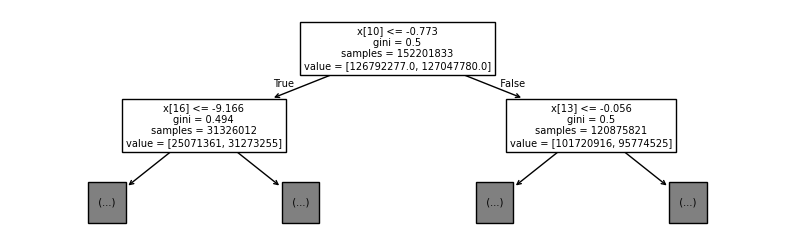

Most important: [ 6 15 27 30 36 39 33 48 24 21 63 60 45 42 57  9 54 51 18 12  3  0]


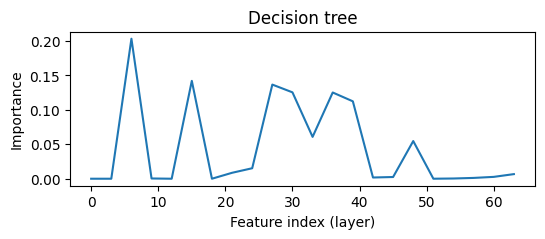

RANDOM FOREST
Most important: [33 30 27 24 36 21 18 15  9 39 12  6 42  3  0 63 51 45 60 48 57 54]


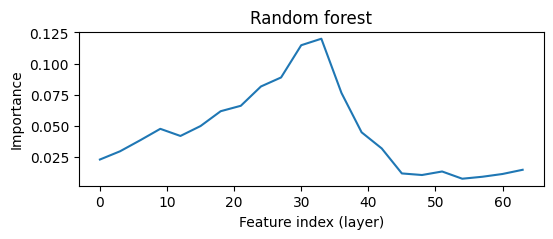

CATBOOST
Most important: [27 30 33 39 36 24  9 15  3 21  0 12 18 63  6 45 57 60 42 51 54 48]


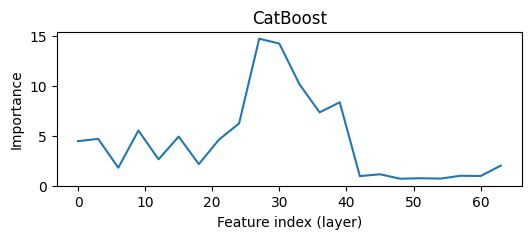

In [12]:
display(e3_runs)
analyze(e3_trained_models, list(range(0, 65, 3)))

#### CT: every 4th layer

In [ ]:
e4_trained_models, e4_runs = run_experiment("Every_4th", list(range(0, 65, 4)))

Decision stump: F0.5=0.1302
Logistic regression: F0.5=0.1311
Decision tree: F0.5=0.1314
Random forest: F0.5=0.1324
Gradient boosting: F0.5=0.1328
CatBoost: F0.5=0.1332


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Every_4th,0.130192,0.488338,0.515451,0.109332,0.549669,0.182387,0.100344
1,Logistic regression,Every_4th,0.131072,0.334993,0.520721,0.108654,0.750344,0.189821,0.104863
2,Decision tree,Every_4th,0.131416,0.321243,0.535527,0.108846,0.770463,0.190744,0.105427
3,Random forest,Every_4th,0.132442,0.284390,0.537356,0.109464,0.825816,0.193305,0.106994
4,Gradient boosting,Every_4th,0.132776,0.317886,0.541031,0.109940,0.784948,0.192867,0.106725
5,CatBoost,Every_4th,0.133222,0.325118,0.542501,0.110353,0.778868,0.193316,0.107000


DECISION STUMP


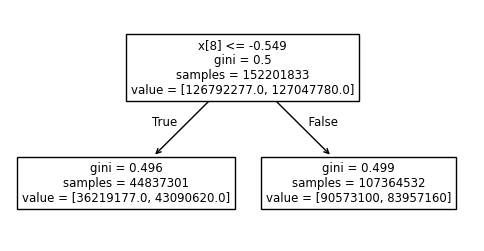

LOGISTIC REGRESSION


feature name,0,4,8,12,16,20,24,28,32,36,40,44,48,52,56,60,64
weight,0.011248,0.016428,0.021839,0.02207,0.025981,0.034742,0.024735,-0.00223,0.003229,-0.02391,-0.021812,-0.014381,-0.002991,0.000197,-0.00155,-0.00457,-0.009928


Intercept: -0.00023742185498535148
Most important: [20 16 24 36 12  8 40  4 44  0 64 60 32 48 28 56 52]


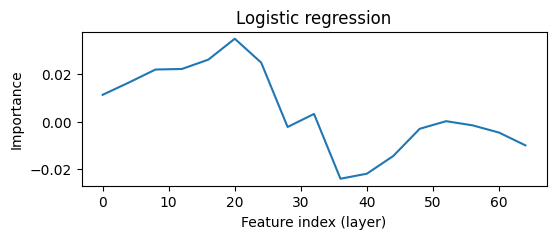

DECISION TREE


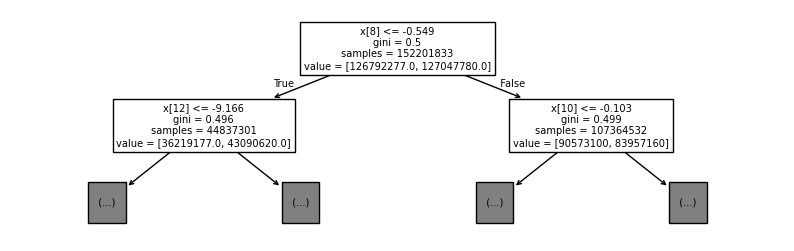

Most important: [28 16 32 40  0 48 36 24 64  8 60 20 52 12  4 44 56]


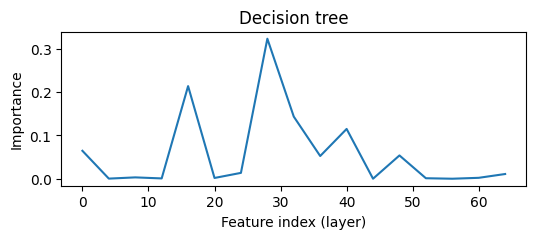

RANDOM FOREST
Most important: [32 28 36 20 24 16 12 40  4  8  0 44 64 52 60 48 56]


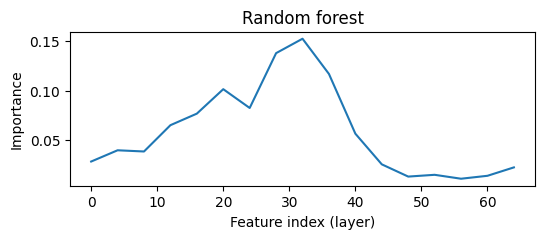

CATBOOST
Most important: [28 32 24 36  0 40 20 16  8  4 12 64 56 44 60 52 48]


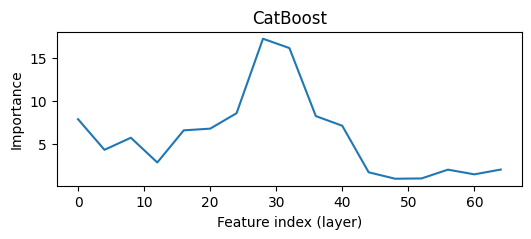

In [ ]:
display(e4_runs)
analyze(e4_trained_models, list(range(0, 65, 4)))

#### CT: inner layers

In [13]:
inner_trained_models, inner_runs = run_experiment("Inner", list(range(0, 16)))

Decision stump: F0.5=0.1312
Logistic regression: F0.5=0.1311
Decision tree: F0.5=0.1313
Random forest: F0.5=0.1324
Gradient boosting: F0.5=0.1324
CatBoost: F0.5=0.1322


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Inner,0.131159,0.430373,0.518171,0.109494,0.628977,0.186518,0.102851
1,Logistic regression,Inner,0.131138,0.349670,0.520043,0.108809,0.732053,0.189458,0.104641
2,Decision tree,Inner,0.131267,0.165786,0.529065,0.107940,0.968405,0.194231,0.107561
3,Random forest,Inner,0.132371,0.187845,0.534721,0.108932,0.950193,0.195457,0.108314
4,Gradient boosting,Inner,0.132396,0.226264,0.532360,0.109125,0.900693,0.194665,0.107828
5,CatBoost,Inner,0.132203,0.260807,0.530298,0.109140,0.854400,0.193555,0.107147


DECISION STUMP


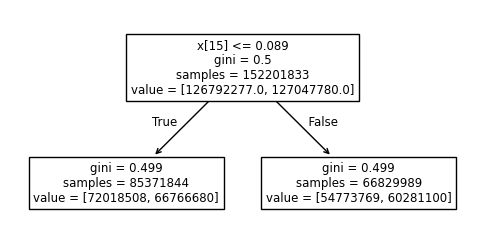

LOGISTIC REGRESSION


feature name,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
weight,0.005127,-0.003055,0.00583,0.012006,-0.001831,-0.004732,0.0066,0.016368,0.004222,-0.012503,-0.002278,0.02596,0.033618,-0.021855,-0.073845,0.094641


Intercept: 0.0012991218777822448
Most important: [15 14 12 11 13  7  9  3  6  2  0  5  8  1 10  4]


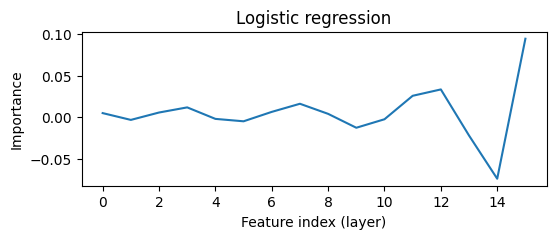

DECISION TREE


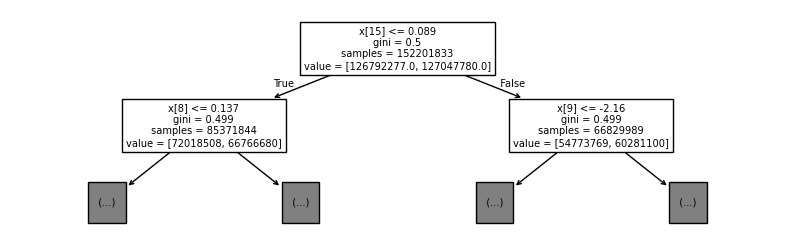

Most important: [13  1  2  7  8  4 15 12 11  6  9  5 14  0 10  3]


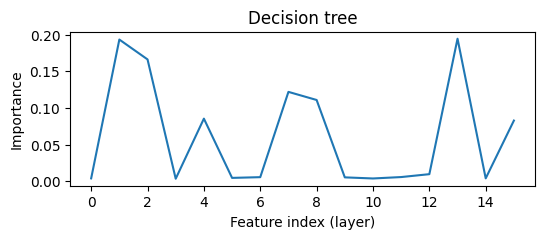

RANDOM FOREST
Most important: [15  0  1  2 14 13  4  6 12  5  3  9 11  7 10  8]


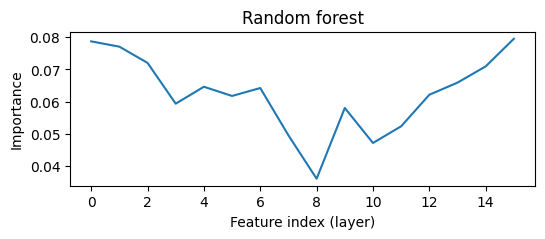

CATBOOST
Most important: [15  0  8  5 11  9  4 12 13  2  6 14  1  3  7 10]


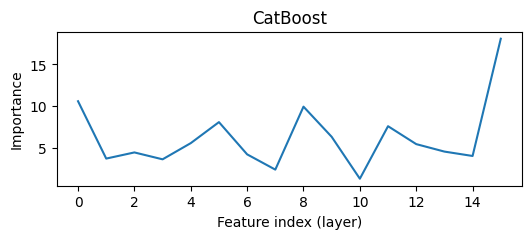

In [14]:
display(inner_runs)
analyze(inner_trained_models, list(range(0, 16)))

#### CT: middle layers

In [15]:
middle_trained_models, middle_runs = run_experiment("Middle", list(range(20, 41)))

Decision stump: F0.5=0.1294
Logistic regression: F0.5=0.1312
Decision tree: F0.5=0.1325
Random forest: F0.5=0.1331
Gradient boosting: F0.5=0.1338
CatBoost: F0.5=0.1347


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Middle,0.129445,0.546536,0.513800,0.109559,0.472485,0.177874,0.097619
1,Logistic regression,Middle,0.131206,0.366997,0.518450,0.108991,0.710362,0.188986,0.104354
2,Decision tree,Middle,0.132514,0.306791,0.543994,0.109656,0.797364,0.192798,0.106683
3,Random forest,Middle,0.133107,0.305162,0.544888,0.110132,0.804021,0.193728,0.107253
4,Gradient boosting,Middle,0.133848,0.307090,0.550791,0.110751,0.807182,0.194777,0.107897
5,CatBoost,Middle,0.134733,0.323953,0.554393,0.111584,0.791667,0.195599,0.108401


DECISION STUMP


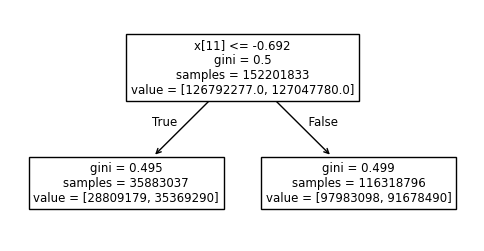

LOGISTIC REGRESSION


feature name,20,21,22,23,24,25,26,27,28,29,...,31,32,33,34,35,36,37,38,39,40
weight,0.081706,-0.046188,-0.021657,0.028859,0.02906,-0.004301,-0.01423,0.003187,0.013164,0.000542,...,-0.006062,0.00561,0.014136,0.004689,-0.013048,-0.022527,-0.00971,0.013871,0.016514,-0.046339


Intercept: 0.000616732883281666
Most important: [20 40 21 24 23 36 22 39 26 33 30 38 28 35 37 31 32 34 25 27 29]


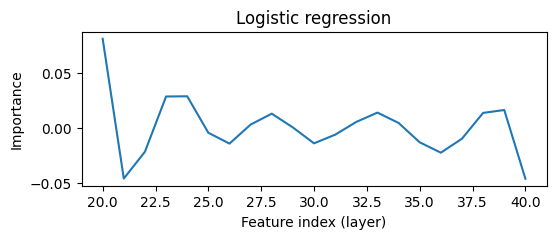

DECISION TREE


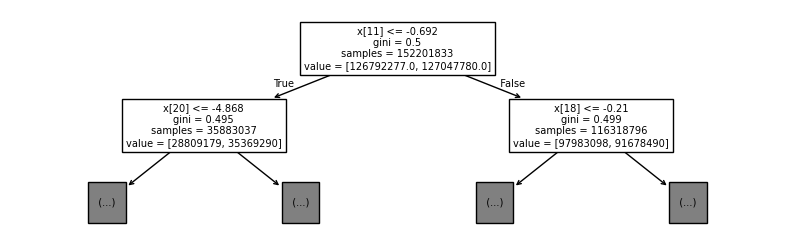

Most important: [21 31 30 38 24 20 27 40 36 33 28 29 26 25 22 32 35 34 23 37 39]


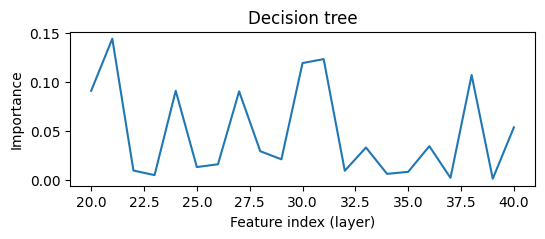

RANDOM FOREST
Most important: [28 26 31 30 21 27 32 33 25 29 23 36 35 22 37 20 24 38 34 39 40]


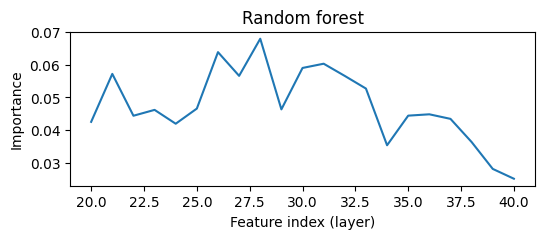

CATBOOST
Most important: [20 30 28 25 35 31 36 29 33 40 21 32 22 27 23 37 24 26 34 38 39]


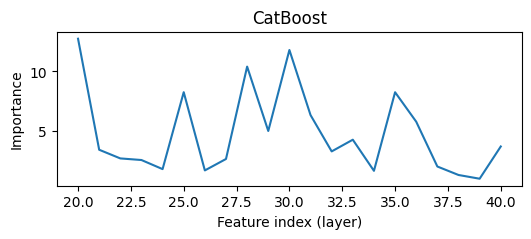

In [16]:
display(middle_runs)
analyze(middle_trained_models, list(range(20, 41)))

#### CT: outer layers

In [17]:
outer_trained_models, outer_runs = run_experiment("Outer", list(range(45, 65)))

Decision stump: F0.5=0.1265
Logistic regression: F0.5=0.1230
Decision tree: F0.5=0.1225
Random forest: F0.5=0.1208
Gradient boosting: F0.5=0.1213
CatBoost: F0.5=0.1221


,Model,Experiment,F0.5,Accuracy,AUC-ROC,Precision,Recall,F1-score,Jaccard score
0,Decision stump,Outer,0.126542,0.104190,0.500204,0.103862,1.000000,0.188179,0.103862
1,Logistic regression,Outer,0.123036,0.490981,0.498282,0.103430,0.508936,0.171921,0.094045
2,Decision tree,Outer,0.122525,0.406526,0.492256,0.102154,0.605481,0.174815,0.095779
3,Random forest,Outer,0.120842,0.468554,0.490258,0.101352,0.523568,0.169828,0.092794
4,Gradient boosting,Outer,0.121257,0.467336,0.491695,0.101683,0.527211,0.170484,0.093185
5,CatBoost,Outer,0.122066,0.436506,0.492583,0.102041,0.567618,0.172985,0.094682


DECISION STUMP


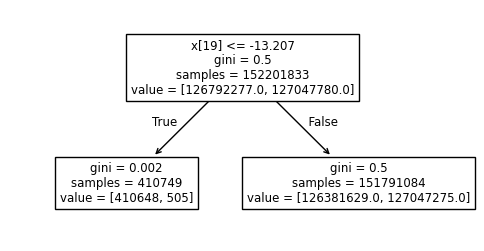

LOGISTIC REGRESSION


feature name,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64
weight,-0.036561,0.011548,0.015468,0.004306,-0.001808,-0.004085,-0.000041,0.004134,0.006754,0.001603,-0.00226,-0.003629,-0.00013,0.005105,0.004087,-0.001581,-0.003972,-0.004039,-0.002581,-0.001293


Intercept: 0.0021508753682728445
Most important: [45 47 46 53 58 48 52 59 50 62 61 56 63 55 49 54 60 64 57 51]


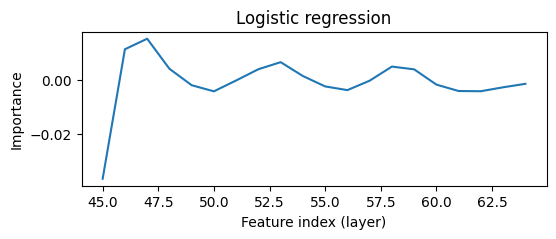

DECISION TREE


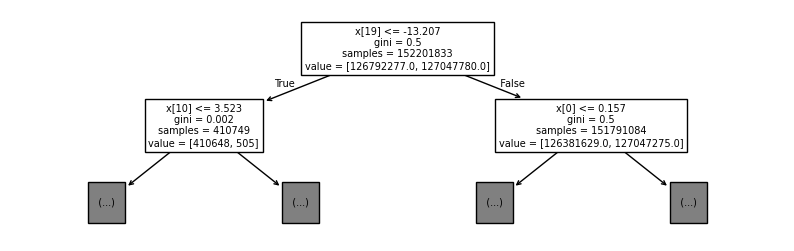

Most important: [64 45 51 57 63 62 60 50 46 52 54 56 58 55 59 48 53 47 49 61]


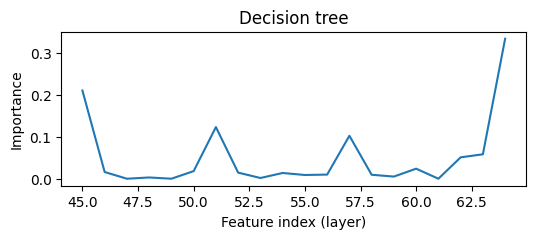

RANDOM FOREST
Most important: [64 62 45 61 63 60 59 57 46 58 56 55 51 47 53 52 50 54 48 49]


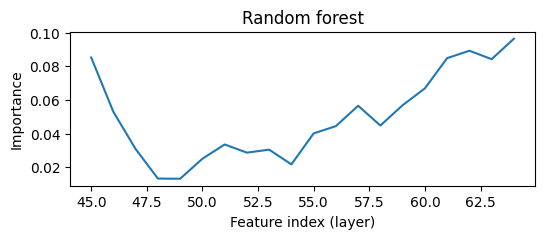

CATBOOST
Most important: [57 45 64 51 62 47 55 59 52 49 48 53 50 46 61 60 56 63 58 54]


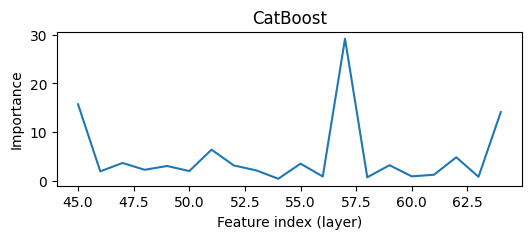

In [18]:
display(outer_runs)
analyze(outer_trained_models, list(range(45, 65)))

#### Results

Expectedly, infrared scans provide a significantly better opportunity for good predictions, with all models exceeding 0.31 $F_{0.5}$ score except for the logistic regression.

CT scans, however, show much more depressing results. Even the best models only barely improve upon the dummy classifier that predicts inc in every pixel ($F_{0.5} = 0.12649$). The best results from each section are the following:
```
CatBoost	Every_2nd	0.134024
CatBoost	Every_3rd	0.133919
CatBoost	Every_4th	0.133222
Gradient boosting	Inner	0.132396
CatBoost	Middle	0.134733
Decision stump	Outer	0.126542
```
Expectedly, middle layers show the best results - even better than selecting every 2nd layer. Therefore, our assumptions about layer importances are probably correct. This is also supported by the analyses of the models: both logistic regression coefficients and tree/forest/boosting feature importances have a clear peak around layers 20-40.

Before going into deep learning, in the further experiments, we will employ catboost using midline layers from 15 to 45 with a stride of 2. This should be a reasonable balance between quality, memory usage, and speed.

#### Best result

In [8]:
DEPTHS = [20, 23, 26, 28, 30, 31, 32, 33, 35, 37, 40]

Learning rate set to 0.5
0:	learn: 0.6942571	total: 3.44s	remaining: 5m 40s
1:	learn: 0.6873806	total: 6.17s	remaining: 5m 2s
2:	learn: 0.6831441	total: 9.34s	remaining: 5m 2s
3:	learn: 0.6818268	total: 12.1s	remaining: 4m 50s
4:	learn: 0.6800108	total: 15s	remaining: 4m 44s
5:	learn: 0.6791747	total: 17.9s	remaining: 4m 40s
6:	learn: 0.6776338	total: 21.1s	remaining: 4m 40s
7:	learn: 0.6774815	total: 23.3s	remaining: 4m 28s
8:	learn: 0.6774623	total: 25.8s	remaining: 4m 21s
9:	learn: 0.6766048	total: 28.5s	remaining: 4m 16s
10:	learn: 0.6762237	total: 31.2s	remaining: 4m 12s
11:	learn: 0.6758678	total: 33.8s	remaining: 4m 7s
12:	learn: 0.6756259	total: 36.6s	remaining: 4m 4s
13:	learn: 0.6756122	total: 38.8s	remaining: 3m 58s
14:	learn: 0.6754180	total: 41.8s	remaining: 3m 56s
15:	learn: 0.6752226	total: 44.6s	remaining: 3m 54s
16:	learn: 0.6750514	total: 47.1s	remaining: 3m 50s
17:	learn: 0.6746234	total: 49.9s	remaining: 3m 47s
18:	learn: 0.6745804	total: 52.8s	remaining: 3m 45s
19:

{'F0.5': 0.2352711054334603,
 'Accuracy': 0.5418105575640472,
 'AUC-ROC': 0.6011838813484894,
 'Precision': 0.20417512415908298,
 'Recall': 0.6020276387356001,
 'F1-score': 0.30493338287429816,
 'Jaccard score': 0.17989463056700922}

{'F0.5': 0.13475759362167555,
 'Accuracy': 0.3238540677447032,
 'AUC-ROC': 0.5545224190592347,
 'Precision': 0.11160399403894493,
 'Recall': 0.7919855644373954,
 'F1-score': 0.19563916245655882,
 'Jaccard score': 0.10842574189479365}

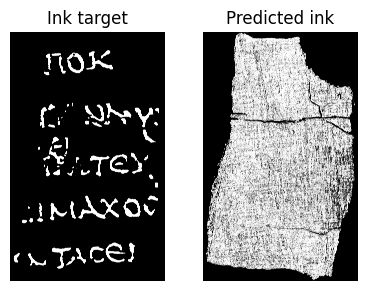

In [9]:
train_X, train_y = load_fragments([1, 2, 3], depths=DEPTHS)
test_X, test_y = load_fragments([4], depths=DEPTHS)

ss = sklearn.preprocessing.StandardScaler(copy=False)
train_X = ss.fit_transform(train_X)
test_X = ss.transform(test_X)

model = catboost.CatBoostClassifier(
    class_weights=[1, 5], iterations=100, depth=4, random_seed=42
)
model = model.fit(train_X, train_y)

display(estimate_quality(model.predict_proba(train_X)[:, 1], train_y))

preds = model.predict_proba(test_X)[:, 1]
display(estimate_quality(preds, test_y))
plot_prediction(preds, fragment=4, ax=None)

Well... Kinda terrible